# Build Forcing Validation - Temperature
- Tony Grove

In [5]:
%matplotlib ipympl
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from buildforcing.datasets import PNNLSnotel
#from gdriver.gdriver import get_credentials, getCSVtoPandas
import os

In [6]:
# Run parameters
site = 'Tony Grove RS'
latitude = 41.89
longitude = -111.57
start_date = '20151001'
end_date = '20161001'
buildforcing_version = 'v0.4.4'
build_settings = '00000010'  # 00000010 - Temperature corrected
#environment = '/home/chriscox/Data/'
environment = 'C:/Users/clmbn/NMT_PhD/data/' # Windows

In [7]:
# Create a data extraction function for forcing data
def get_forcing_values(forcing_file, variable, start_date, end_date) -> pd.DataFrame:
    """
    Extract forcing values from a NetCDF file for a given variable and date range.
    
    Parameters:
        forcing_file (str): Path to the NetCDF file.
        variable (str): Variable name to extract.
        start_date (str): Start date in 'YYYYMMDD' format.
        end_date (str): End date in 'YYYYMMDD' format.

    Returns:
        pd.DataFrame: DataFrame containing the extracted values.
    """
    ds = xr.open_dataset(forcing_file)
    subset = ds[variable].isel(latitude=0, longitude=0)
    df: pd.DataFrame = subset.to_dataframe()
    ds.close() # Seems to help when running in Jupyter Notebook

    df = df.loc[start_date:end_date]
    
    return df

### Load datasets

In [9]:
# Load the forcing dataset
sitename = site.replace(' ', '').lower()
datapath = os.path.join(environment, 'forcing', sitename, f'{sitename}_{start_date}_{end_date}_s{build_settings}_{buildforcing_version}.nc')
forcing_Tair = get_forcing_values(datapath, 'Tair', start_date, end_date)


In [10]:
# Convert temperature from Kelvin to Celsius
forcing_Tair['Tair_C'] = forcing_Tair['Tair'] - 273.15
forcing_Tair.index = forcing_Tair.index.tz_localize('UTC').tz_convert('America/Denver')

In [11]:
snotel = PNNLSnotel(site_name=site, storage_path=os.path.join(environment, 'snotel'))

In [ ]:
snotel.data.head()

In [12]:
nldas_forcing = xr.open_dataset(os.path.join(environment,'nldas',f'NLDAS_{latitude}_{longitude}_{start_date}_{end_date}.nc'))

In [13]:
nldas_Tair = nldas_forcing['Tair'].to_dataframe()
nldas_Tair['Tair_C'] = nldas_Tair['Tair'] - 273.15
nldas_Tair.index = nldas_Tair.index.tz_localize('UTC').tz_convert('America/Denver')

#### Load GAMUT

In [14]:
gamut_st110 = pd.read_csv(
    os.path.join(environment, 'gamut/tonygrovers', f'LR_TG_C_AirTemp_ST110_Avg_SourceID_1_QC_1.csv'),
    skiprows=56
    )

# Create datetime index from LocalDateTime
gamut_st110.index = pd.DatetimeIndex(
    pd.to_datetime(gamut_st110['LocalDateTime'], format='%Y-%m-%d %H:%M:%S')
)

# I only need 2015-2016 data
gamut_st110 = gamut_st110.loc['2015-10-01':'2016-10-01']

In [16]:
# Replace -9999 with NaN
gamut_st110.replace(-9999, np.nan, inplace=True)

## Comparisons

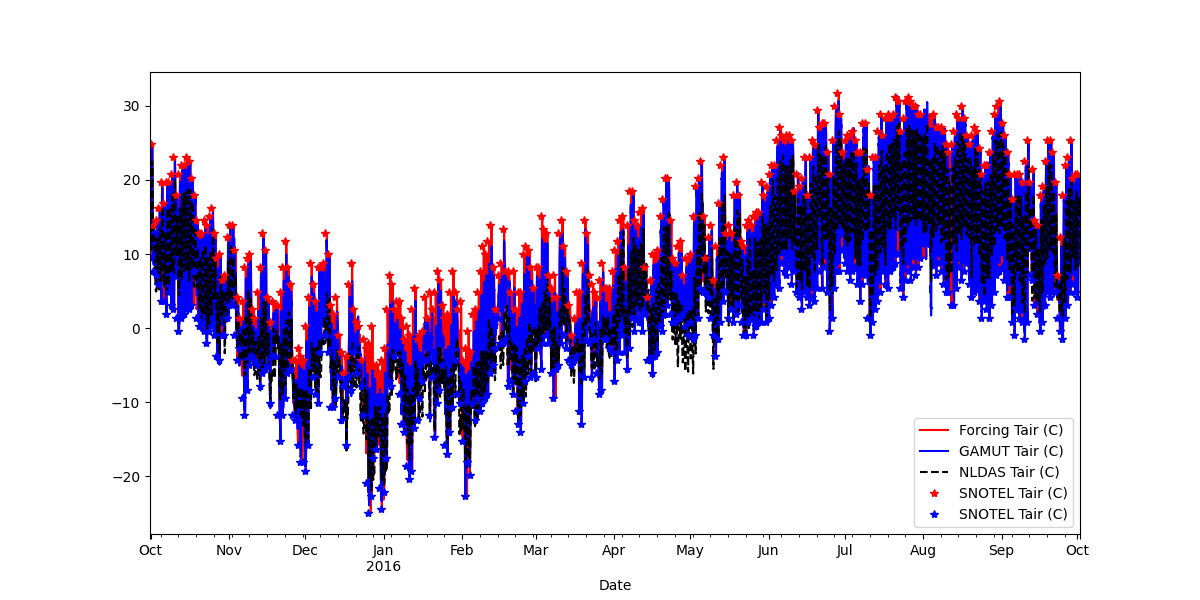

In [17]:
# Plot Tair and compare to ST110 data
fig, ax = plt.subplots(figsize=(12, 6))
forcing_Tair['Tair_C'].plot(ax=ax, label='Forcing Tair (C)', color='r', linestyle='-')
gamut_st110['AirTemp_ST110_Avg'].plot(ax=ax, label='GAMUT Tair (C)', color='b', linestyle='-')
nldas_Tair['Tair_C'].loc[start_date:end_date].plot(ax=ax, label='NLDAS Tair (C)', color='k', linestyle='--')
snotel.data.loc[start_date:end_date,'T_max_C'].plot(ax=ax, label='SNOTEL Tair (C)', color='r', marker='*', linestyle='None')
snotel.data.loc[start_date:end_date,'T_min_C'].plot(ax=ax, label='SNOTEL Tair (C)', color='b', marker='*', linestyle='None')
ax.legend()

In [ ]:
# Load Tair V0 for comparison
sitename = site.replace(' ', '').lower()
datapath_v0 = os.path.join(environment,'forcing',f'{sitename}_{start_date}_{end_date}_v0.1.0.nc')
forcing_Tair_v0 = get_forcing_values(datapath_v0, 'Tair', start_date, end_date)
forcing_Tair_v0['Tair_C'] = forcing_Tair_v0['Tair'] - 273.15
forcing_Tair_v0.index = forcing_Tair_v0.index.tz_localize('UTC').tz_convert('America/Denver')

<Axes: xlabel='DateTime'>

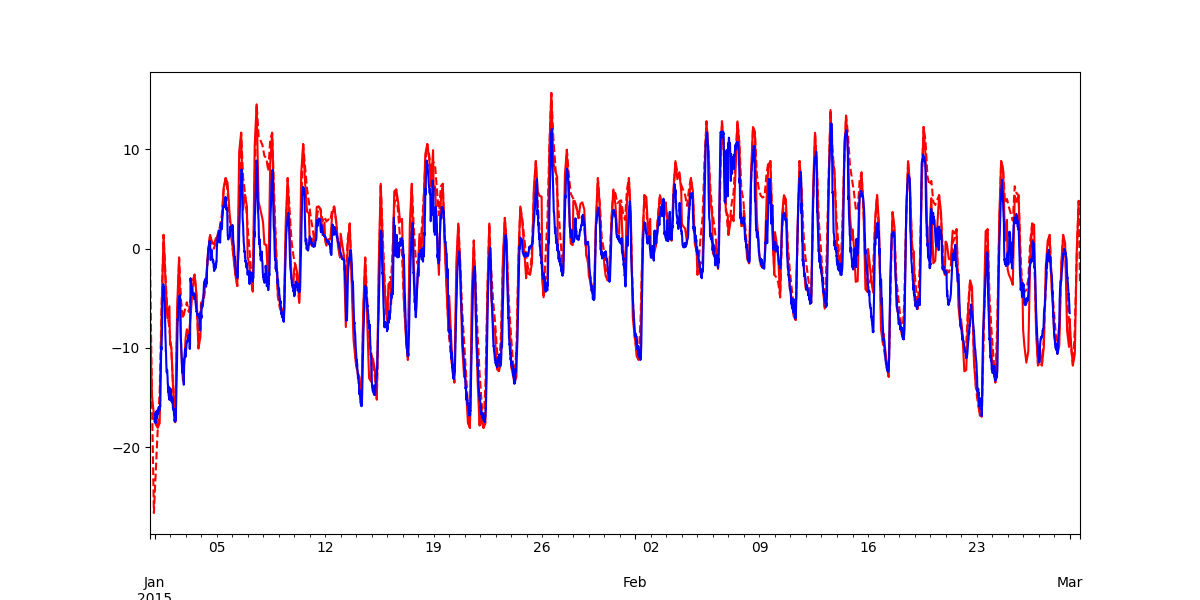

In [ ]:
# Compare Tair V0 to V1
fig, ax = plt.subplots(figsize=(12, 6))
forcing_Tair['Tair_C'].plot(ax=ax, label='Forcing Tair V1 (C)', color='r', linestyle='-')
forcing_Tair_v0['Tair_C'].plot(ax=ax, label='Forcing Tair V0 (C)', color='r', linestyle='--')
gamut_st110_month['AirTemp_ST110_Avg'].plot(ax=ax, label='GAMUT Tair (C)', color='b', linestyle='-')


#